# GDP data exploration
GDP (US$, in trillions) for the UK, USA, Brazil, Japan, China, Germany and Switzerland, 2000-2022. Source: World Bank.

In [1]:
# Import plotting/data libraries and our own functions from the fed package
import matplotlib.pyplot as plt
import pandas as pd

from fed.data import download_gdp
from fed.plot_utils import plot_gdp

    year  United Kingdom  United States    Brazil     Japan      China  \
0   2000        1.671598      10.250952  0.655448  5.042382   1.223755   
1   2001        1.656171      10.581929  0.559984  4.438793   1.355037   
2   2002        1.790537      10.929108  0.509795  4.245947   1.489822   
3   2003        2.061228      11.456450  0.558234  4.573413   1.683903   
4   2004        2.429775      12.217196  0.669289  4.941485   1.984197   
5   2005        2.551362      13.039197  0.891634  4.875648   2.317551   
6   2006        2.719558      13.815583  1.107627  4.648059   2.791498   
7   2007        3.104700      14.474228  1.397114  4.624670   3.604056   
8   2008        2.945252      14.769862  1.695855  5.160197   4.667346   
9   2009        2.429358      14.478067  1.666996  5.336766   5.189577   
10  2010        2.496741      15.048971  2.208838  5.811578   6.192565   
11  2011        2.675590      15.599732  2.616156  6.279423   7.671757   
12  2012        2.719716      16.25397

## 1. Load the data

In [2]:
# Download GDP data from the World Bank and preview the first 5 rows
df = download_gdp()
df.head()

,year,United Kingdom,United States,Brazil,Japan,China,Germany,Switzerland
0,2000,1.671598,10.250952,0.655448,5.042382,1.223755,1.966981,0.282327
1,2001,1.656171,10.581929,0.559984,4.438793,1.355037,1.966381,0.290160
2,2002,1.790537,10.929108,0.509795,4.245947,1.489822,2.102351,0.313931
3,2003,2.061228,11.456450,0.558234,4.573413,1.683903,2.534716,0.366564
4,2004,2.429775,12.217196,0.669289,4.941485,1.984197,2.852318,0.409013


## 2. Structure and summary statistics

In [3]:
# Check the size of the dataframe (rows, columns) and each column's type and non-null count
print(df.shape)
df.info()

(23, 8)
<class 'pandas.DataFrame'>
RangeIndex: 23 entries, 0 to 22
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   year            23 non-null     int64  
 1   United Kingdom  23 non-null     float64
 2   United States   23 non-null     float64
 3   Brazil          23 non-null     float64
 4   Japan           23 non-null     float64
 5   China           23 non-null     float64
 6   Germany         23 non-null     float64
 7   Switzerland     23 non-null     float64
dtypes: float64(7), int64(1)
memory usage: 1.6 KB


In [4]:
# Summary statistics (mean, std, min, quartiles, max) for each column
df.describe().round(2)

,year,United Kingdom,United States,Brazil,Japan,China,Germany,Switzerland
count,23.00,23.00,23.00,23.00,23.00,23.00,23.00,23.00
mean,2011.00,2.62,16.41,1.59,5.07,8.03,3.39,0.60
std,6.78,0.45,4.33,0.68,0.53,5.66,0.70,0.18
min,2000.00,1.66,10.25,0.51,4.25,1.22,1.97,0.28
25%,2005.50,2.46,13.43,1.00,4.64,2.55,2.97,0.44
50%,2011.00,2.72,15.60,1.70,5.04,7.67,3.54,0.70
75%,2016.50,2.92,19.21,2.01,5.24,12.00,3.88,0.73
max,2022.00,3.19,26.05,2.62,6.33,18.32,4.36,0.86


In [5]:
# Count missing values in each column (all zeros means no gaps in the data)
df.isna().sum()

year              0
United Kingdom    0
United States     0
Brazil            0
Japan             0
China             0
Germany           0
Switzerland       0
dtype: int64

## 3. GDP over time

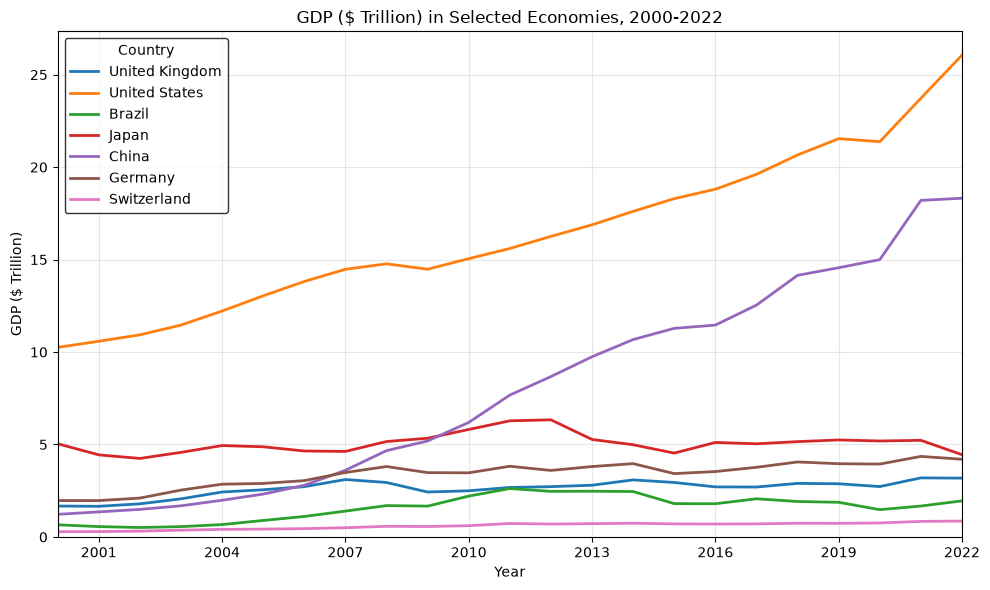

In [6]:
# Line chart of GDP over time, one colour per country
plot_gdp()
plt.show()

## 4. 2000 vs 2022: size, growth and ranking

In [7]:
# Compare 2000 and 2022: GDP, how many times larger it became, compound annual
# growth rate (CAGR) and each country's rank by GDP in each year
gdp = df.set_index("year")
years = gdp.index.max() - gdp.index.min()

summary = pd.DataFrame(
    {
        "GDP 2000": gdp.loc[2000],
        "GDP 2022": gdp.loc[2022],
    }
)
summary["Change (x)"] = summary["GDP 2022"] / summary["GDP 2000"]
summary["CAGR (%)"] = ((summary["Change (x)"] ** (1 / years)) - 1) * 100
summary["Rank 2000"] = summary["GDP 2000"].rank(ascending=False).astype(int)
summary["Rank 2022"] = summary["GDP 2022"].rank(ascending=False).astype(int)
summary.sort_values("GDP 2022", ascending=False).round(2)

,GDP 2000,GDP 2022,Change (x),CAGR (%),Rank 2000,Rank 2022
United States,10.25,26.05,2.54,4.33,1,1
China,1.22,18.32,14.97,13.09,5,2
Japan,5.04,4.45,0.88,-0.57,2,3
Germany,1.97,4.20,2.14,3.51,3,4
United Kingdom,1.67,3.18,1.90,2.97,4,5
Brazil,0.66,1.95,2.98,5.09,6,6
Switzerland,0.28,0.86,3.04,5.18,7,7


## 5. Year-on-year growth

In [8]:
# Year-on-year GDP growth (%) for each country, with summary statistics
growth = gdp.pct_change() * 100
growth.describe().round(2)

,United Kingdom,United States,Brazil,Japan,China,Germany,Switzerland
count,22.00,22.00,22.00,22.00,22.00,22.00,22.00
mean,3.33,4.37,6.42,-0.24,13.37,3.80,5.38
std,8.77,2.81,16.94,8.13,8.26,7.95,6.61
min,-17.52,-1.98,-26.62,-16.76,0.63,-13.61,-4.72
25%,-0.88,3.38,-4.90,-4.59,9.47,-0.43,1.39
50%,2.81,4.24,4.90,0.10,12.59,4.72,3.45
75%,7.92,5.20,19.53,6.64,18.95,8.90,10.45
max,17.88,11.00,33.22,12.70,29.50,20.57,19.22


In [9]:
# Best and worst year of growth for each country, and the growth rate in that year
pd.DataFrame(
    {
        "Best year": growth.idxmax(),
        "Best growth (%)": growth.max().round(1),
        "Worst year": growth.idxmin(),
        "Worst growth (%)": growth.min().round(1),
    }
)

,Best year,Best growth (%),Worst year,Worst growth (%)
United Kingdom,2004,17.9,2009,-17.5
United States,2021,11.0,2009,-2.0
Brazil,2005,33.2,2015,-26.6
Japan,2016,12.7,2013,-16.8
China,2008,29.5,2022,0.6
Germany,2003,20.6,2015,-13.6
Switzerland,2011,19.2,2015,-4.7


## 6. Share of the total across these seven economies

In [11]:
# Each country's share (%) of the combined GDP of the seven economies, for selected years
share = gdp.div(gdp.sum(axis=1), axis=0) * 100
share.loc[[2000, 2010, 2022]].round(1)

,United Kingdom,United States,Brazil,Japan,China,Germany,Switzerland
year,,,,,,,
2000,7.9,48.6,3.1,23.9,5.8,9.3,1.3
2010,7.0,42.0,6.2,16.2,17.3,9.7,1.7
2022,5.4,44.2,3.3,7.5,31.0,7.1,1.5


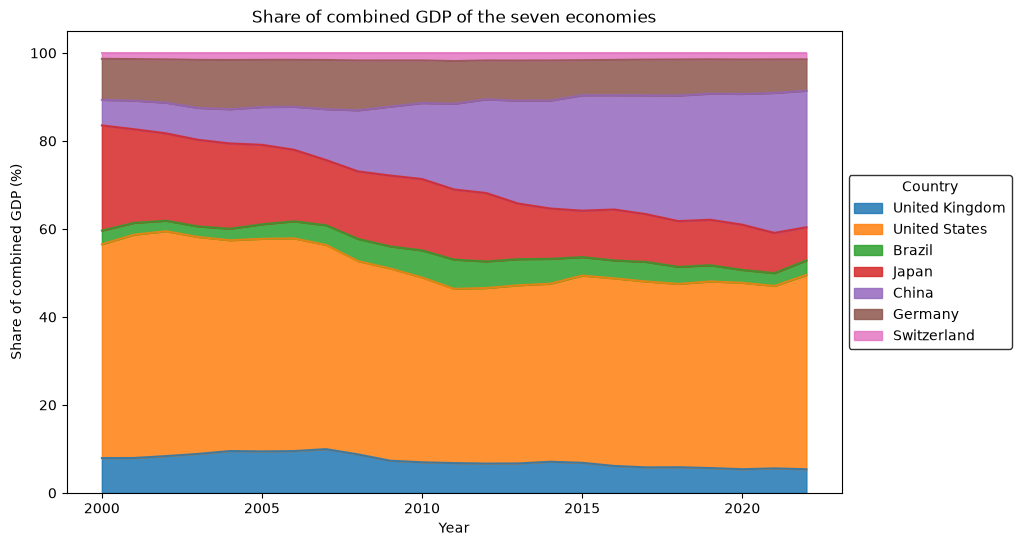

In [12]:
# Stacked area chart of each country's share of combined GDP over time
fig, ax = plt.subplots(figsize=(10, 6))
share.plot.area(ax=ax, alpha=0.85)
ax.set_xlabel("Year")
ax.set_ylabel("Share of combined GDP (%)")
ax.set_title("Share of combined GDP of the seven economies")
ax.legend(title="Country", loc="center left", bbox_to_anchor=(1, 0.5), frameon=True, edgecolor="black")
plt.show()

## Summary: GDP developments, 2000-2022

Between 2000 and 2022 the combined GDP of these seven economies rose from about \$21tn to \$59tn (current US\$). The main developments were:

- **The US stayed the largest economy.** Its GDP grew from \$10.3tn to \$26.1tn (approximately 4.3% a year), with only small dips in 2009 (due to the Global Financial Crisis) and around 49% to 44%.
- **China's rise is the dominant story.** GDP grew from \$1.2tn to \$18.3tn (around 13% a year, a roughly 15 times increase). China passed the UK in 2006, Germany in 2007 and Japan in 2010, and has been second only to the US since. Its share of the combined total rose from about 6% to 31%.
- **Japan was the only economy to shrink.** It started second at \$5.0tn, peaking at around \$6.3tn in 2012 and ended third at \$4.4tn. Part of the decline in dollar terms reflects a weaker yen, not solely slow growth.
- **Germany and the UK roughly doubled**, to \$4.2tn and \$3.2tn (growing at around 3.5% and 3.0% a year). Both slowed after the 2008-09 financial crisis and again in 2020 due to COVID.
- **Brazil and Switzerland grew fastest among the smaller economies** (at approximately 5% a year). Brazil's GDP peaked at about \$2.6tn in 2011 and fell back sharply, while Switzerland rose steadily to \$0.9tn.
- **Common shocks:** the 2008-09 financial crisis and the 2020 pandemic are visible as dips in several economies at once. The US and China recovered quickly, and by 2021 most economies were above their pre-pandemic levels.

These figures are in nominal US dollars, so exchange-rate changes affect them as well as real economic growth.